In [17]:
import numpy as np
import matplotlib.pyplot as plt

In [21]:
class0 = np.random.randn(100, 2) * 1.5 + np.array([2, 2])
class1 = np.random.randn(50, 2) * 1.5 + np.array([6, 6])

X = np.vstack((class0, class1))
y = np.hstack((np.zeros(100), np.ones(50)))

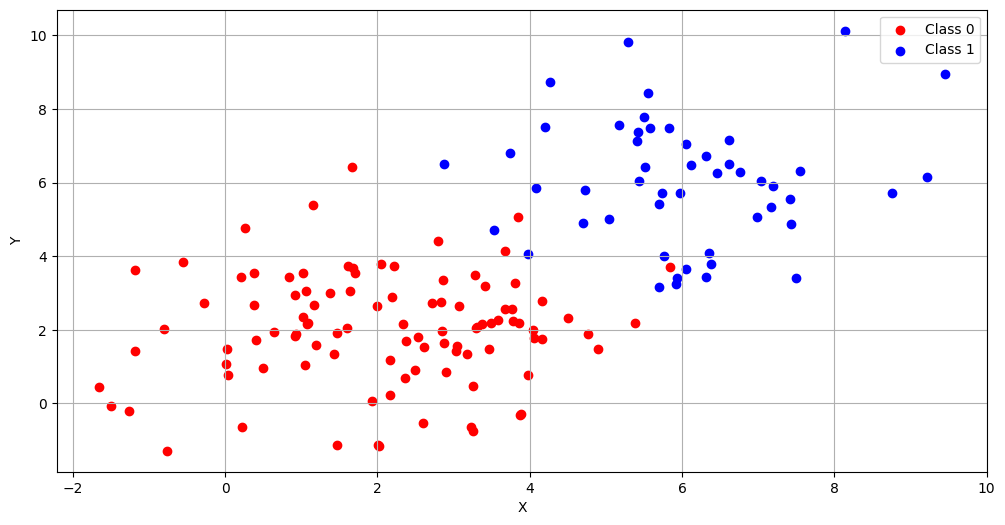

In [22]:
plt.figure(figsize=(12,6))
plt.xlabel("X")
plt.ylabel("Y")
plt.scatter(X[:100, 0], X[:100, 1], color='red', label='Class 0')
plt.scatter(X[100:, 0], X[100:, 1], color='blue', label='Class 1')
plt.legend()
plt.grid()
plt.show()

In [23]:
def kmeans(X, k, iterations):
  random_indices = np.random.choice(len(X), k, replace=False)
  centroids = X[random_indices]
  for i in range(iterations):
    distances = np.zeros((len(X), k))
    for j in range(k):
      distances[:, j] = np.sqrt(np.sum((X - centroids[j])**2, axis=1))
    clusters = np.argmin(distances, axis=1)
    new_centroids = np.zeros((k, X.shape[1]))
    for j in range(k):
      if(len(X[clusters == j]) > 0):
        new_centroids[j] = np.mean(X[clusters == j], axis=0)
      else:
        new_centroids[j] = centroids[j]
    if np.allclose(centroids, new_centroids):
      break
    centroids = new_centroids
  return centroids, clusters


In [24]:
k = 2
centroids, clusters = kmeans(X, k, 100)
print(f"Centoids: \n{centroids}")
print(f"Cluster-0 points: {np.sum(clusters==0)}")
print(f"Cluster-1 points: {np.sum(clusters==1)}")

Centoids: 
[[2.02712984 1.91628855]
 [5.8824307  5.96553046]]
Cluster-0 points: 97
Cluster-1 points: 53


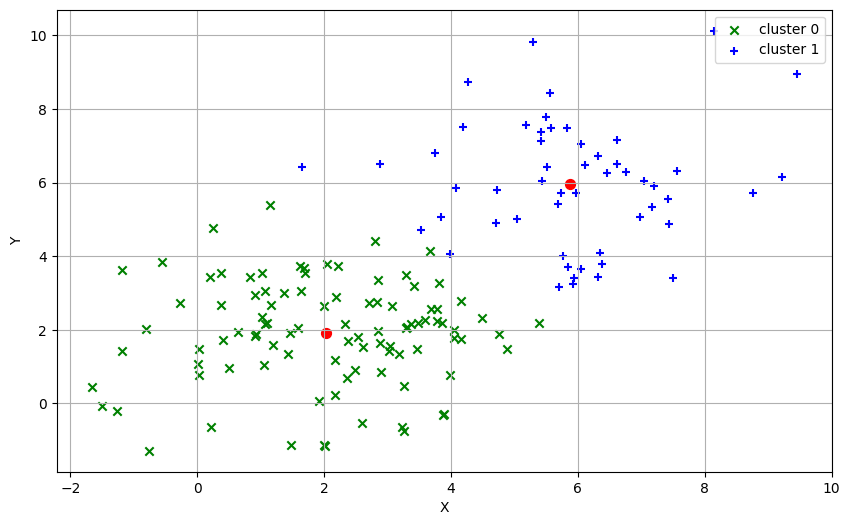

In [25]:
plt.figure(figsize=(10,6))
plt.scatter(X[clusters==0, 0], X[clusters==0, 1], color='green', marker='x', label='cluster 0')
plt.scatter(X[clusters==1, 0], X[clusters==1, 1], color='blue', marker='+', label='cluster 1')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='o', s=50)
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid()
plt.show()


In [30]:
direct_accuracy = np.sum(clusters==y)
reverse_accuracy = np.sum((1-clusters)==y)

if direct_accuracy > reverse_accuracy:
  y_pred = clusters
else:
  y_pred = 1-clusters

In [32]:
#print("Actual | Predicted")
#print("==================")
#for i in range(len(y)):
#  print(f"{int(y[i])}\t|\t{y_pred[i]}")

In [34]:
TP = TN = FP = FN = 0

for i in range(len(y)):
  if y[i]==1 and y_pred[i]==1:
    TP += 1
  elif y[i]==0 and y_pred[i]==1:
    FP += 1
  elif y[i]==1 and y_pred[i]==0:
    FN += 1
  elif y[i]==0 and y_pred[i]==0:
    TN += 1

confusion_matrix = np.array([[TP, FP], [FN, TN]])
print(f"Confusion Matrix: \n{confusion_matrix}")

Confusion Matrix: 
[[50  3]
 [ 0 97]]


In [35]:
accuracy = (TP + TN) / (TP + TN + FN + FP)
precision = TP / (TP + FP) if (TP + FP)!=0 else 0
recall = TP / (TP + FN) if (TP + FN)!=0 else 0
f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) !=0 else 0

In [36]:
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")

Accuracy: 0.9800
Precision: 0.9434
Recall: 1.0000
F1 Score: 0.9709
